# Analyse Exeperiments Results #

In [34]:
import numpy as np
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

import sys
sys.path.append("/home/gavrilev/Thesis/src")

from utils.plot_utils import plot_horizontal_metric, plot_grouped_metrics

## MultiStructRSA Hyperparameter Search

To optimize the MultiStructRSA architecture, we conducted a progressive hyperparameter search in the following order:

1. **Global hyperparameter search**  
   In this stage, we examined the following hyperparameters: learning rate, weight decay, and dropout, where the same dropout value was used for both the MLPs and the BiDirectionalCrossFusion module.  
   The tested search space was:  
   `{'learning_rate': [1e-5, 2e-5, 5e-5], 'weight_decay': [1e-5, 1e-6], 'dropout': [0.1, 0.2]}`  
   This resulted in `3 × 2 × 2 = 12` experiments.

2. **SMILES module hyperparameter search**  
   In this stage, we evaluated three encoding strategies for the sequence-based features (SimSon and ChemBERTa) and for the expert-based features (Morgan fingerprints and Mordred descriptors).  
   Specifically, we tested:  
   `{'smiles_seq_setting': ['proj', 'shallow', 'deep'], 'smiles_expert_setting': ['proj', 'shallow', 'deep']}`  

   The settings are defined as follows:  
   - `proj`: a simple projection of the input into a lower-dimensional space of size 256, followed by `LayerNorm`.  
   - `shallow`: a shallow MLP with one hidden layer, using the structure `input -> 512 -> 256`. For each layer except the output layer, we applied `LayerNorm -> ReLU -> dropout`.  
   - `deep`: similar to the shallow setting, but with two hidden layers, using the structure `input -> 512 -> 512 -> 256`.  

   In total, this stage included `3 × 3 = 9` experiments.

3. **RNA module hyperparameter search**  
   In this stage, we optimized the BiDirectionalCrossFusion module in two steps.  
   First, we examined the following hyperparameters:  
   `{'d_model': [128, 256], 'ffn_mult': [4, 6], 'bdcf_blocks': [1, 2]}`  

   After selecting the best configuration, we then evaluated the pooling strategies:  
   `{'d_model_ffn_mult_bdcf_blocks': [(128, 4, 1), (128, 4, 2), (256, 4, 1)]'token_pool': ['mean', 'attn'], 'node_pool': ['mean', 'attn']}`  

   In total, the RNA module hyperparameter search included  
   `2 × 2 × 2 + 1 × 2 × 2 = 8 + 4 = 12` experiments.de_pool': ['mean', 'attn']}`

### MultiStruct Global Hyperparameter Search ###

In [35]:
def preprocess_df_hyperparam_plot(path):
    hyperparam_df = pd.read_csv(path)
    exp_description = ['_'.join(exp.split('_')[1:]) for exp in hyperparam_df['exp']]
    hyperparam_df['exp_description'] = exp_description
    return hyperparam_df

In [36]:
GLOBAL_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1304.csv'

In [37]:
glob_hyperparam = pd.read_csv(GLOBAL_HYPERPARAM_PATH)
glob_hyperparam.head()

,exp,family,n_samples,p_mean,p_std,s_mean,s_std,rmse_mean,rmse_std,r2_mean,r2_std,per_fold
0,exp6_lr=5e-5_wd=1e-6_dropout=0.2,all_families,1439,0.78977,0.02473,0.79731,0.01594,0.85948,0.05352,0.62029,0.03814,"{'p': [0.79330844, 0.7528811, 0.7838398, 0.788..."
1,exp7_lr=5e-5_wd=1e-5_dropout=0.1,all_families,1439,0.79081,0.01559,0.79594,0.00872,0.86299,0.03752,0.61758,0.02469,"{'p': [0.7885734, 0.77100027, 0.7782594, 0.802..."
2,exp3_lr=2e-5_wd=1e-5_dropout=0.1,all_families,1439,0.80074,0.02744,0.81101,0.02316,0.83989,0.06033,0.63712,0.04325,"{'p': [0.80817264, 0.7756531, 0.7640726, 0.816..."
3,exp5_lr=5e-5_wd=1e-6_dropout=0.1,all_families,1439,0.80065,0.02480,0.80400,0.01531,0.84149,0.05628,0.63564,0.04123,"{'p': [0.7829648, 0.7724196, 0.79616106, 0.807..."
4,exp4_lr=2e-5_wd=1e-5_dropout=0.2,all_families,1439,0.79549,0.02116,0.80224,0.02012,0.84732,0.05057,0.63109,0.03474,"{'p': [0.81075704, 0.76334345, 0.78807867, 0.7..."


In [38]:
exp_description = ['_'.join(exp.split('_')[1:]) for exp in glob_hyperparam['exp']]
exp_description

['lr=5e-5_wd=1e-6_dropout=0.2',
 'lr=5e-5_wd=1e-5_dropout=0.1',
 'lr=2e-5_wd=1e-5_dropout=0.1',
 'lr=5e-5_wd=1e-6_dropout=0.1',
 'lr=2e-5_wd=1e-5_dropout=0.2',
 'lr=2e-5_wd=1e-6_dropout=0.2',
 'lr=2e-5_wd=1e-6_dropout=0.1',
 'lr=1e-5_wd=1e-6_dropout=0.2',
 'lr=1e-5_wd=1e-5_dropout=0.1',
 'lr=5e-5_wd=1e-5_dropout=0.2',
 'lr=1e-5_wd=1e-5_dropout=0.2',
 'lr=1e-5_wd=1e-6_dropout=0.1']

In [39]:
glob_hyperparam['exp_description'] = exp_description

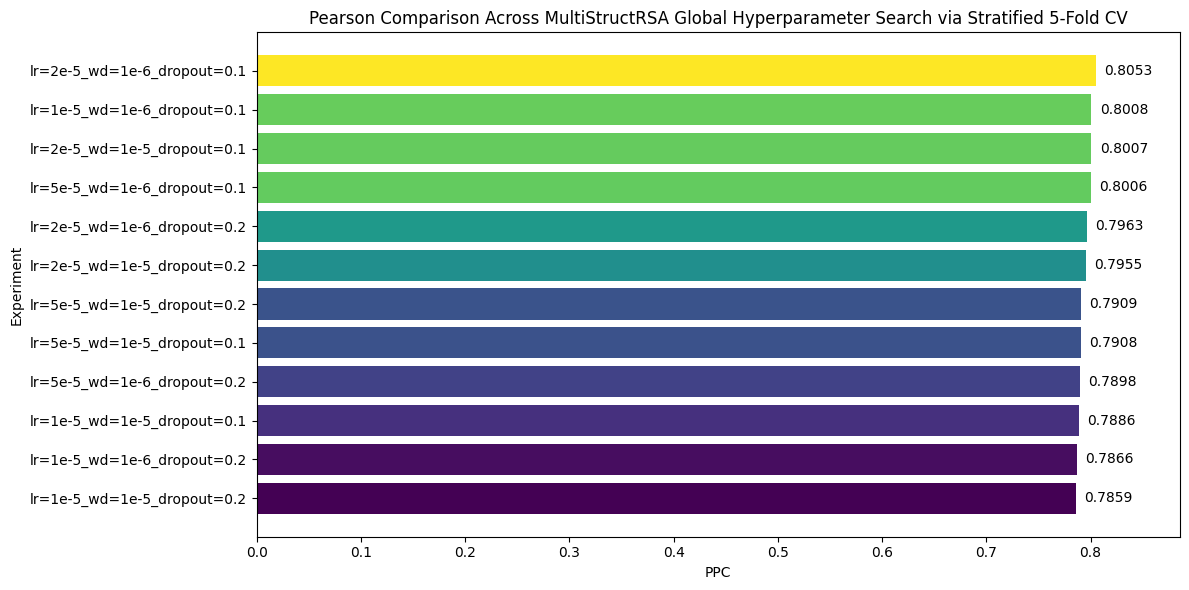

In [40]:
plot_horizontal_metric(
    df=glob_hyperparam,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA Global Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

### RNA Module Hyperparameter Search ###

In [41]:
RNA_BDCF_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1504.csv'
RNA_POOL_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1604.csv'

In [ ]:
rna_bdcf_hyperparam = preprocess_df_hyperparam_plot(RNA_BDCF_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=rna_bdcf_hyperparam,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

In order to keep the final SMILES encoder dimension at 256, we will continue with the first and third best configurations above, namely (128, 4, 1) and (128, 4, 2), and tune the BiDirectionalCrossFusion pooling mechanisms on the node and token sides.

**Note**: We keep the dimension at 256 because, after pooling the node and token features, we concatenate them along the feature dimension, resulting in an RNA representation of 128 + 128 = 256. If we choose d_model = 256, this would become 256 + 256 = 512. In that case, we would need to perform additional experiments and tuning on the SMILES side as well. Since the differences in performance are not large enough to justify that, we examine two configurations that differ only in the number of BiDirectionalCrossFusion blocks (1 vs. 2).

In [ ]:
rna_pool_hyperparam_df = preprocess_df_hyperparam_plot(RNA_POOL_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=rna_pool_hyperparam_df,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

we'll keep tuning MultiStructRSA with the configuration that gave us the best results, and then we'll conduct another experiment with the second best con

### Small Molecule Hyperparameter Search ###

In [10]:
SMILES_HYPERPARAM_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1704.csv'

In [ ]:
smiles_encoding_hyperparam_df = preprocess_df_hyperparam_plot(SMILES_HYPERPARAM_PATH)

plot_horizontal_metric(
    df=smiles_encoding_hyperparam_df,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()

## MultiStructRSA Sensitivity Analysis

After stabilizing the MultiStructRSA architecture through an extensive hyperparameter search, the next step is to perform a sensitivity analysis in order to identify which features in both the RNA and small-molecule modules actually contribute to the model’s performance and which are redundant.  

To this end, we will perform stratified 5-fold cross-validation and remove one feature at a time in each experiment, in order to examine how each feature affects the overall performance of MultiStructRSA.

In [13]:
SENSITIVITY_ANALYSIS1_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1804.csv'

In [16]:
sensitivity_analysis1_df

,exp,family,n_samples,p_mean,p_std,s_mean,s_std,rmse_mean,rmse_std,r2_mean,r2_std,per_fold,exp_description
0,exp3_w/o=mordred,all_families,1439,0.76404,0.02878,0.76762,0.02847,0.90365,0.05714,0.58025,0.04360,"{'p': [0.7784045, 0.71163857, 0.75505, 0.78889...",w/o=mordred
1,exp1_w/o=chemberta,all_families,1439,0.80087,0.02944,0.80738,0.01877,0.84133,0.06222,0.63560,0.04691,"{'p': [0.793971, 0.7503561, 0.8134373, 0.80635...",w/o=chemberta
2,exp2_w/o=simson,all_families,1439,0.79683,0.03326,0.80432,0.03420,0.85028,0.07178,0.62768,0.05305,"{'p': [0.8284029, 0.76097095, 0.7590848, 0.796...",w/o=simson
3,exp4_w/o=morgan,all_families,1439,0.80481,0.01497,0.80884,0.01027,0.83133,0.03649,0.64504,0.02422,"{'p': [0.80007887, 0.785548, 0.8079717, 0.7993...",w/o=morgan
4,exp0_w/o=None,all_families,1439,0.79529,0.01950,0.79991,0.01406,0.85195,0.04188,0.62721,0.02859,"{'p': [0.7984435, 0.7607417, 0.79120034, 0.807...",w/o=None
5,exp7_w/o=grnade,all_families,1439,0.78245,0.02881,0.79371,0.01879,0.87248,0.05848,0.60863,0.04305,"{'p': [0.7945559434340339, 0.7349768189283452,...",w/o=grnade
6,exp6_w/o=ernie,all_families,1439,0.79798,0.02176,0.80612,0.01700,0.84721,0.05004,0.63118,0.03451,"{'p': [0.8079287971512485, 0.7650708879989168,...",w/o=ernie
7,exp5_w/o=rinalmo,all_families,1439,0.78957,0.02151,0.79682,0.00864,0.85987,0.04718,0.62007,0.03367,"{'p': [0.7855828027034022, 0.7543213367514454,...",w/o=rinalmo


In [ ]:
sensitivity_analysis1_df = preprocess_df_hyperparam_plot(SENSITIVITY_ANALYSIS1_PATH)

plot_horizontal_metric(
    df=sensitivity_analysis1_df,
    label_col="exp_description",
    value_col="rmse_mean",
    title="RMSE Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="RMSE",
    ylabel="Experiment",
    sort_ascending=False
)

plt.show()

We observe slightly worse results with the full model compared to the earlier experiments (0.8060 previously versus 0.7953 now). We speculate that this difference may be due to variance in the model, which could be reduced by running more than a single stratified 5-fold cross-validation experiment, for example by performing five runs with different random seeds. 

Moreover, the sensitivity analysis pipeline includes additional parameters and weights in the initialization of MultiStructRSA to make the experiments easier to run under different hyperparameter configurations. Even when some hyperparameters are not used, and their corresponding weights and gradients do not participate in learning or change during training (for example, when the SimSon feature is excluded), their initialization may still affect the randomness and overall weight initialization of the model.

As shown in the figure above, excluding Morgan fingerprints led to the largest improvement in performance. Therefore, we will conduct an additional sensitivity analysis without Morgan fingerprints.

In [20]:
SENSITIVITY_ANALYSIS2_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1904_.csv'

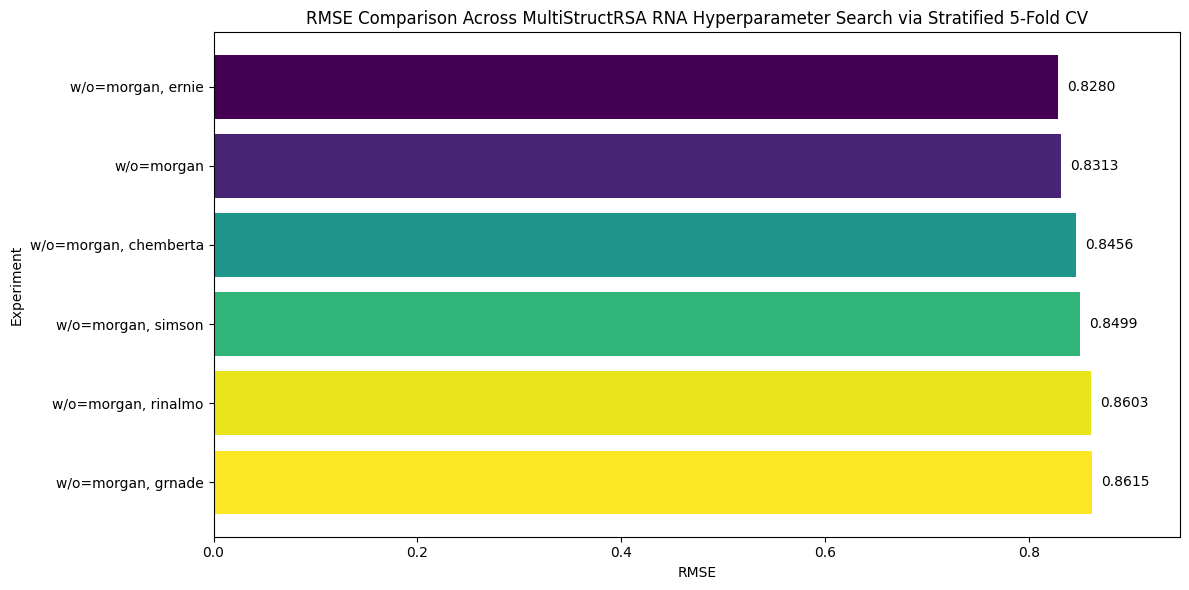

In [22]:
sensitivity_analysis2_df = preprocess_df_hyperparam_plot(SENSITIVITY_ANALYSIS2_PATH)

plot_horizontal_metric(
    df=sensitivity_analysis2_df,
    label_col="exp_description",
    value_col="rmse_mean",
    title="RMSE Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="RMSE",
    ylabel="Experiment",
    sort_ascending=False
)

plt.show()

## MultiStructRSA Ablation Study ##

The following experiments are designed to examine the contribution of predicted RNA 3D structures to RNA–small molecule binding affinity prediction.

The predicted RNA 3D structures were obtained using the AlphaFold3 server. These structures were then processed using the pre-trained gRNAde framework, originally developed for inverse RNA folding. We extracted the pre-trained weights (via Hugging Face) and fine-tuned only the GNN encoder, which takes RNA structural information as input and produces node and edge representations.

In addition, we introduced a cross-modal fusion mechanism named **BiDirectionalCrossFusion**, which integrates RNA graph features with sequence-based language embeddings. This mechanism is based on nucleotide-level cross-attention, where each graph node *i* corresponds to nucleotide *i* in both the structural graph and the sequence embedding space.

Overall, the ablation study evaluates the following model configurations:

1. **w/o 3D structure** – excludes predicted RNA 3D structures (i.e., no AlphaFold3 + gRNAde features)
2. **w/o sequence** – excludes pre-trained RNA language model embeddings (RiNALMo)
3. **w/o fusion** – removes the BiDirectionalCrossFusion module (features are combined via simple concatenation)
4. **MultiStructRSA (frozen)** – full model with frozen gRNAde weights (to assess the contribution of fine-tuning)
5. **MultiStructRSA (full)** – full model with trainable gRNAde encoder

In [23]:
ABLATION_STUDY_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_2004_.csv'

In [ ]:
ablation_study_df = preprocess_df_hyperparam_plot(ABLATION_STUDY_PATH)

plot_horizontal_metric(
    df=ablation_study_df,
    label_col="exp_description",
    value_col="rmse_mean",
    title="RMSE Comparison Across MultiStructRSA RNA Hyperparameter Search via Stratified 5-Fold CV",
    xlabel="RMSE",
    ylabel="Experiment",
    sort_ascending=False
)

plt.show()

In [26]:
ablation_study_df

,exp,setting,family,n_samples,p_mean,p_std,s_mean,s_std,rmse_mean,rmse_std,r2_mean,r2_std,per_fold,exp_description
0,exp2_w/o 3D Struct,w/o 3D struct,all_families,1439,0.79286,0.01544,0.79985,0.01312,0.85632,0.03706,0.62349,0.02373,"{'p': [0.7999435, 0.7775575, 0.7836511, 0.7832...",w/o 3D Struct
1,exp1_w/o Fusion,w/o fusion,all_families,1439,0.79535,0.01219,0.80372,0.00613,0.85103,0.03351,0.62809,0.02202,"{'p': [0.78847724, 0.7854926, 0.78850496, 0.79...",w/o Fusion
2,exp3_MultiStructRSA (frozen),full (frozen),all_families,1439,0.79937,0.02920,0.80448,0.02201,0.84056,0.05993,0.63645,0.04486,"{'p': [0.8034716382844636, 0.7449251121272908,...",MultiStructRSA (frozen)
3,exp0_MultiStructRSA,full,all_families,1439,0.80721,0.01858,0.80949,0.01460,0.82798,0.04054,0.64769,0.02894,"{'p': [0.789212805055854, 0.7876610469966181, ...",MultiStructRSA
4,exp4_w/o Seq,w/o seq,all_families,1439,0.75001,0.04860,0.75939,0.03237,0.92334,0.07976,0.56058,0.06893,"{'p': [0.7690558295270762, 0.654386441134875, ...",w/o Seq


In [27]:
exp_description = ['_'.join(exp.split('_')[1:]) for exp in ablation_study_df['exp']]
ablation_study_df = ablation_study_df[["rmse_mean", "p_mean", "s_mean"]]
ablation_study_df['exp_description'] = exp_description

/tmp/ipykernel_4108989/2446037097.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ablation_study_df['exp_description'] = exp_description


In [28]:
ablation_study_df

,rmse_mean,p_mean,s_mean,exp_description
0,0.85632,0.79286,0.79985,w/o 3D Struct
1,0.85103,0.79535,0.80372,w/o Fusion
2,0.84056,0.79937,0.80448,MultiStructRSA (frozen)
3,0.82798,0.80721,0.80949,MultiStructRSA
4,0.92334,0.75001,0.75939,w/o Seq


In [29]:
order = ['w/o 3D Struct', 'w/o Seq', 'w/o Fusion', 'MultiStructRSA (frozen)', 'MultiStructRSA']
ablation_study_df['exp_description'] = pd.Categorical(ablation_study_df['exp_description'], categories=order,ordered=True)

ablation_study_df = ablation_study_df.sort_values('exp_description').reset_index(drop=True)
cols = ['exp_description'] + [c for c in ablation_study_df.columns if c != 'exp_description']
ablation_study_df = ablation_study_df[cols]

/tmp/ipykernel_4108989/1740806950.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ablation_study_df['exp_description'] = pd.Categorical(ablation_study_df['exp_description'], categories=order,ordered=True)


In [30]:
ablation_study_df

,exp_description,rmse_mean,p_mean,s_mean
0,w/o 3D Struct,0.85632,0.79286,0.79985
1,w/o Seq,0.92334,0.75001,0.75939
2,w/o Fusion,0.85103,0.79535,0.80372
3,MultiStructRSA (frozen),0.84056,0.79937,0.80448
4,MultiStructRSA,0.82798,0.80721,0.80949


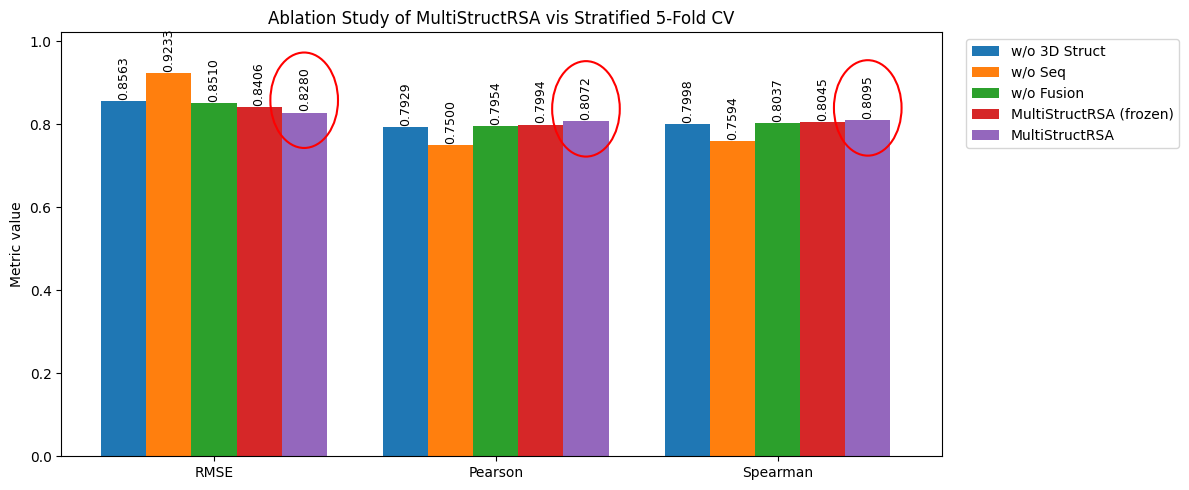

In [31]:
metric_cols = ["rmse_mean", "p_mean", "s_mean"]

metric_labels = {
    "rmse_mean": "RMSE",
    "p_mean": "Pearson",
    "s_mean": "Spearman"
}

exp_order = [
    "w/o 3D Struct",
    "w/o Seq",
    "w/o Fusion",
    "MultiStructRSA (frozen)",
    "MultiStructRSA"
]

plot_grouped_metrics(
    df=ablation_study_df,
    metric_cols=metric_cols,
    exp_col="exp_description",
    exp_order=exp_order,
    metric_labels=metric_labels,
    title="Ablation Study of MultiStructRSA vis Stratified 5-Fold CV",
    lower_is_better=["rmse_mean"]
)

plt.show()